# Decision surfaces of ensembles of trees on iris: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/ensemble/plot_forest_iris.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/ensemble/plot_forest_iris.html)).

**Scenario:** for three pairs of iris features, a `DecisionTreeClassifier`, a `RandomForestClassifier(30)`,
an `ExtraTreesClassifier(30)` and an `AdaBoostClassifier(DecisionTreeClassifier(max_depth=3), 30)` are trained
on shuffled, standardized data. The example prints each training score and plots each member tree's decision
regions (alpha `1/len(estimators_)`) plus the ensemble's predictions on a coarse grid.

**Adaptations**
- **Seeds:** the example leaves `random_state=None` on every model, so its forests differ between runs. Here every
  model gets `random_state=13` (the example's `RANDOM_SEED`, which it already uses for the shuffle), on both sides,
  making the comparison exact. The scientific content of the plot is unchanged.
- **GAP: AdaBoostClassifier** is a raising declaration in Moxie (`NotImplementedError`); its column runs only in
  Python, and an `--expect-fail` cell proves the failure is explicit.
- `DecisionBoundaryDisplay.from_estimator` (no `moxie.inspection`) is replaced by evaluating each member tree on a
  grid with step 0.1 (the display's default resolution is finer) in both libraries and drawing the same
  `contourf` overlays; the grid predictions themselves are compared.
- Moxie forests take Float32 features and Float64 labels; scikit-learn casts `X` to float32 internally.
- The figure is drawn twice at dpi 80 (scikit-learn, then Moxie) instead of `plt.show()`.

**Determinism:** deterministic after fixing the seeds, so scores, member predictions and coarse-grid predictions
must match exactly.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("ensemble/plot_forest_iris")

## 1. scikit-learn (Python reference)

The official loop with fixed seeds; the figure is drawn with the shared `draw` helper.

DecisionTree with features [0, 1] has a score of 0.9266666666666666
RandomForest with 30 estimators with features [0, 1] has a score of 0.9266666666666666
ExtraTrees with 30 estimators with features [0, 1] has a score of 0.9266666666666666
AdaBoost with 30 estimators with features [0, 1] has a score of 0.82
DecisionTree with features [0, 2] has a score of 0.9933333333333333
RandomForest with 30 estimators with features [0, 2] has a score of 0.9933333333333333
ExtraTrees with 30 estimators with features [0, 2] has a score of 0.9933333333333333
AdaBoost with 30 estimators with features [0, 2] has a score of 0.9933333333333333
DecisionTree with features [2, 3] has a score of 0.9933333333333333
RandomForest with 30 estimators with features [2, 3] has a score of 0.9933333333333333


ExtraTrees with 30 estimators with features [2, 3] has a score of 0.9933333333333333
AdaBoost with 30 estimators with features [2, 3] has a score of 0.9866666666666667


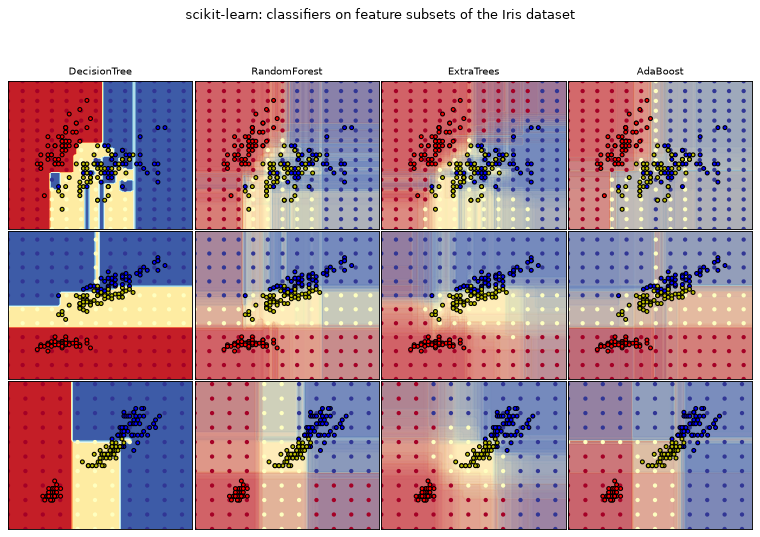

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

from sklearn.datasets import load_iris
from sklearn.ensemble import (
    AdaBoostClassifier,
    ExtraTreesClassifier,
    RandomForestClassifier,
)
from sklearn.tree import DecisionTreeClassifier

# Parameters
n_classes = 3
n_estimators = 30
plot_step_coarser = 0.5  # step widths for coarse classifier guesses
plot_step_fine = 0.1  # grid of the member-tree decision regions (adaptation)
RANDOM_SEED = 13  # fix the seed on each iteration

# Load data
iris = load_iris()

models = [
    DecisionTreeClassifier(max_depth=None, random_state=RANDOM_SEED),
    RandomForestClassifier(n_estimators=n_estimators, random_state=RANDOM_SEED),
    ExtraTreesClassifier(n_estimators=n_estimators, random_state=RANDOM_SEED),
    AdaBoostClassifier(DecisionTreeClassifier(max_depth=3), n_estimators=n_estimators,
                       random_state=RANDOM_SEED),
]
pairs = ([0, 1], [0, 2], [2, 3])
sk, shared = {}, {}
for p, pair in enumerate(pairs):
    for m, model in enumerate(models):
        # We only take the two corresponding features
        X = iris.data[:, pair]
        y = iris.target

        # Shuffle
        idx = np.arange(X.shape[0])
        np.random.seed(RANDOM_SEED)
        np.random.shuffle(idx)
        X = X[idx]
        y = y[idx]

        # Standardize
        mean = X.mean(axis=0)
        std = X.std(axis=0)
        X = (X - mean) / std

        # Train
        model.fit(X, y)

        scores = model.score(X, y)
        # Create a title for each column and the console by using str() and
        # slicing away useless parts of the string
        model_title = str(type(model)).split(".")[-1][:-2][: -len("Classifier")]

        model_details = model_title
        if hasattr(model, "estimators_"):
            model_details += " with {} estimators".format(len(model.estimators_))
        print(model_details + " with features", pair, "has a score of", scores)

        x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
        y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
        xx_coarser, yy_coarser = np.meshgrid(
            np.arange(x_min, x_max, plot_step_coarser),
            np.arange(y_min, y_max, plot_step_coarser),
        )
        xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step_fine), np.arange(y_min, y_max, plot_step_fine))
        coarse = np.c_[xx_coarser.ravel(), yy_coarser.ravel()]
        fine = np.c_[xx.ravel(), yy.ravel()]
        members = [model] if isinstance(model, DecisionTreeClassifier) else model.estimators_
        sk[p, m] = dict(score=scores, coarse=model.predict(coarse),
                        members=np.stack([t.predict(fine) for t in members]),
                        X=X, y=y, xx=xx, yy=yy, xc=xx_coarser, yc=yy_coarser)
    shared[f"X_{p}"], shared[f"C_{p}"], shared[f"G_{p}"] = X, coarse, fine
    shared["y"] = y.astype(np.float64)
nb.share(**shared)

def draw(results, title, columns):
    fig, axes = plt.subplots(3, 4, figsize=(10, 7), dpi=80)
    for p in range(3):
        for m in range(4):
            ax = axes[p, m]
            if p == 0:
                ax.set_title(columns[m], fontsize=9)
            r = sk[p, m]
            if (p, m) not in results:
                ax.text(0.5, 0.5, "not available", ha="center", va="center", transform=ax.transAxes)
                ax.set_xticks([]); ax.set_yticks([])
                continue
            out = results[p, m]
            alpha = 1.0 / len(out["members"])
            for z in out["members"]:
                ax.contourf(r["xx"], r["yy"], z.reshape(r["xx"].shape), cmap="RdYlBu", alpha=alpha)
            ax.scatter(r["xc"], r["yc"], s=15, c=out["coarse"].reshape(r["xc"].shape), cmap=plt.cm.RdYlBu,
                       edgecolors="none")
            ax.scatter(r["X"][:, 0], r["X"][:, 1], c=r["y"], cmap=ListedColormap(["r", "y", "b"]),
                       edgecolor="k", s=12)
            ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(title, fontsize=12)
    plt.tight_layout(h_pad=0.2, w_pad=0.2, pad=2.5)
    plt.show()

columns = ["DecisionTree", "RandomForest", "ExtraTrees", "AdaBoost"]
draw(sk, "scikit-learn: classifiers on feature subsets of the Iris dataset", columns)

## 2. Moxie (native Mojo)

The decision tree, random forest and extra-trees columns through Moxie's public API. Member trees come from `estimators_()`.

In [3]:
%%mojo forest_iris
from moxie.ensemble import RandomForestClassifier, ExtraTreesClassifier
from moxie.tree import DecisionTreeClassifier
from moxie_nb_io import load, save, save_floats
import numojo as nm


def stack(rows: List[nm.NDArray[DType.float64]]) raises -> nm.NDArray[DType.float64]:
    var n = rows[0].size
    var out = nm.zeros[DType.float64](nm.Shape(len(rows), n))
    for r in range(len(rows)):
        for i in range(n):
            out.unsafe_set(r * n + i, rows[r].unsafe_get(i))
    return out^


def main() raises:
    var y = load("y")
    for p in range(3):
        var X = load[DType.float32]("X_" + String(p))
        var C = load[DType.float32]("C_" + String(p))
        var G = load[DType.float32]("G_" + String(p))
        var tag = String(p)
        var scores = List[Float64]()

        var tree = DecisionTreeClassifier(max_depth=None, random_state=13)
        _ = tree.fit(X, y)
        scores.append(tree.score(X, y))
        save("coarse_" + tag + "_0", tree.predict(C))
        var single = List[nm.NDArray[DType.float64]]()
        single.append(tree.predict(G))
        save("members_" + tag + "_0", stack(single))

        var forest = RandomForestClassifier(30, random_state=13)
        _ = forest.fit(X, y)
        scores.append(forest.score(X, y))
        save("coarse_" + tag + "_1", forest.predict(C))
        var rf_members = List[nm.NDArray[DType.float64]]()
        for m in range(len(forest)):
            rf_members.append(forest.estimators_()[m].predict(G))
        save("members_" + tag + "_1", stack(rf_members))

        var extra = ExtraTreesClassifier(30, random_state=13)
        _ = extra.fit(X, y)
        scores.append(extra.score(X, y))
        save("coarse_" + tag + "_2", extra.predict(C))
        var et_members = List[nm.NDArray[DType.float64]]()
        for m in range(len(extra)):
            et_members.append(extra.estimators_()[m].predict(G))
        save("members_" + tag + "_2", stack(et_members))

        save_floats("scores_" + tag, scores)
        print("pair", p, "scores (DecisionTree, RandomForest with", len(forest), "estimators, ExtraTrees with",
              len(extra), "estimators):", scores[0], scores[1], scores[2])

pair 0 scores (DecisionTree, RandomForest with 30 estimators, ExtraTrees with 30 estimators): 0.9266666666666666 0.9266666666666666 0.9266666666666666
pair 1 scores (DecisionTree, RandomForest with 30 estimators, ExtraTrees with 30 estimators): 0.9933333333333333 0.9933333333333333 0.9933333333333333
pair 2 scores (DecisionTree, RandomForest with 30 estimators, ExtraTrees with 30 estimators): 0.9933333333333333 0.9933333333333333 0.9933333333333333


AdaBoost is not implemented in Moxie; constructing it fails explicitly.

In [4]:
%%mojo adaboost --expect-fail
from moxie.ensemble import AdaBoostClassifier


def main() raises:
    # AdaBoostClassifier(DecisionTreeClassifier(max_depth=3), n_estimators=30)
    var model = AdaBoostClassifier(n_estimators=30)
    print("unexpectedly constructed AdaBoostClassifier")

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: AdaBoostClassifier.__init__ is an API scaffold



## 3. Side by side and parity

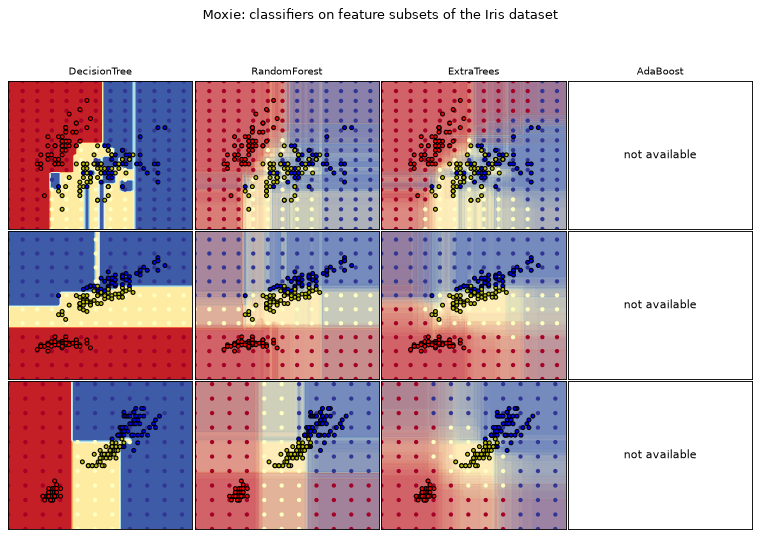

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
training scores (3 pairs x DecisionTree/RandomForest/ExtraTrees),PASS,"(3, 3)","(3, 3)",,,exact,0 mismatches,
DecisionTree: coarse-grid predict (3 pairs),PASS,"(472,)","(472,)",,,exact,0 mismatches,
DecisionTree: member-tree predictions on the 0.1 grid (3 pairs),PASS,"(11128,)","(11128,)",,,exact,0 mismatches,
RandomForest: coarse-grid predict (3 pairs),PASS,"(472,)","(472,)",,,exact,0 mismatches,
RandomForest: member-tree predictions on the 0.1 grid (3 pairs),PASS,"(333840,)","(333840,)",,,exact,0 mismatches,
ExtraTrees: coarse-grid predict (3 pairs),PASS,"(472,)","(472,)",,,exact,0 mismatches,
ExtraTrees: member-tree predictions on the 0.1 grid (3 pairs),PASS,"(333840,)","(333840,)",,,exact,0 mismatches,
AdaBoostClassifier,GAP,,,,,,moxie.ensemble.AdaBoostClassifier is a raising declaration (NotImplementedError); fourth column is reference-only,
DecisionBoundaryDisplay,ADAPTED,,,,,,no moxie.inspection; both sides evaluate member trees on the same 0.1-step grid and draw identical overlays,
random_state,ADAPTED,,,,,,random_state=13 on every model (the example uses None) so forests are reproducible,


In [5]:
mx = nb.results["forest_iris"]
mx_results = {}
for p in range(3):
    for m in range(3):
        mx_results[p, m] = dict(coarse=mx[f"coarse_{p}_{m}"], members=mx[f"members_{p}_{m}"])
draw(mx_results, "Moxie: classifiers on feature subsets of the Iris dataset", columns)

sk_scores = np.array([[sk[p, m]["score"] for m in range(3)] for p in range(3)])
mx_scores = np.stack([mx[f"scores_{p}"] for p in range(3)])
moxie_nb.side_by_side(sklearn=sk_scores, moxie=mx_scores)
nb.compare("training scores (3 pairs x DecisionTree/RandomForest/ExtraTrees)", sk_scores, mx_scores, exact=True)
for m, name in enumerate(columns[:3]):
    nb.compare(f"{name}: coarse-grid predict (3 pairs)",
               np.concatenate([sk[p, m]["coarse"] for p in range(3)]).astype(np.float64),
               np.concatenate([mx[f"coarse_{p}_{m}"] for p in range(3)]), exact=True)
    nb.compare(f"{name}: member-tree predictions on the 0.1 grid (3 pairs)",
               np.concatenate([sk[p, m]["members"].ravel() for p in range(3)]).astype(np.float64),
               np.concatenate([mx[f"members_{p}_{m}"].ravel() for p in range(3)]), exact=True)
nb.note("AdaBoostClassifier", "GAP",
        "moxie.ensemble.AdaBoostClassifier is a raising declaration (NotImplementedError); fourth column is "
        "reference-only")
nb.note("DecisionBoundaryDisplay", "ADAPTED",
        "no moxie.inspection; both sides evaluate member trees on the same 0.1-step grid and draw identical overlays")
nb.note("random_state", "ADAPTED", "random_state=13 on every model (the example uses None) so forests are reproducible")
nb.report()
nb.assert_parity()